In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

## Arima Model

In [4]:
df = pd.read_csv("../Datasets/FMAC-HPI_24420.csv")
df.head()

,Date,NSA Value,SA Value
0,31-01-1975,24.739893,24.687815
1,28-02-1975,25.266825,25.200482
2,31-03-1975,25.765667,25.633002
3,30-04-1975,26.212724,26.009987
4,31-05-1975,26.628081,26.350592


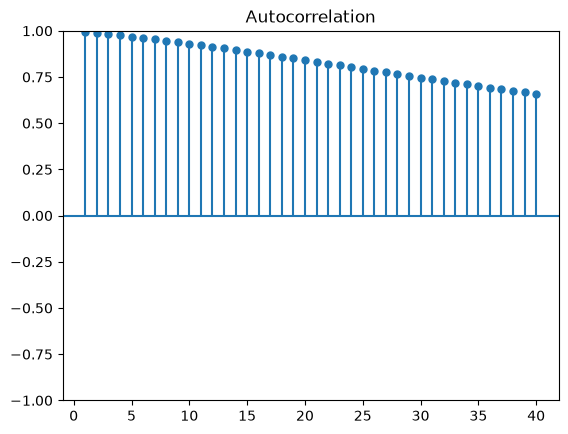

In [6]:
plot_acf(df["NSA Value"], lags=40, alpha=None,zero=False)
plt.show()

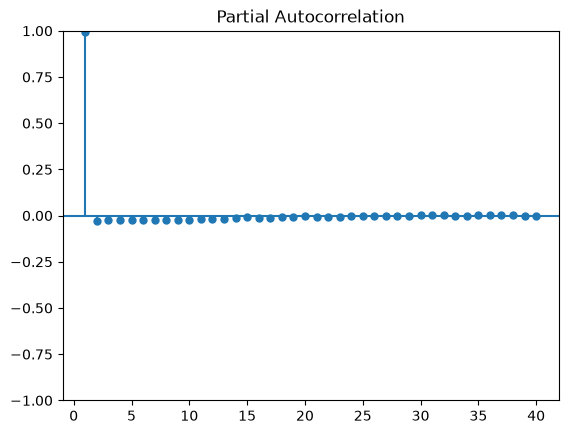

In [7]:
plot_pacf(df["NSA Value"], lags=40, alpha=None,zero=False)
plt.show()

In [8]:
y = df["NSA Value"]
y_train = y[:-12]
y_test = y[-12:]

In [11]:
model = ARIMA(y_train, order=(2,1,1))
model_fit = model.fit()
print("Coefficient %s" % model_fit.params)
pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, pred)
print("Test RMSE : %.2f" % error)

Coefficient ar.L1     1.473144
ar.L2    -0.589775
ma.L1     0.999739
sigma2    0.035254
dtype: float64
Test RMSE : 3.18


<Axes: >

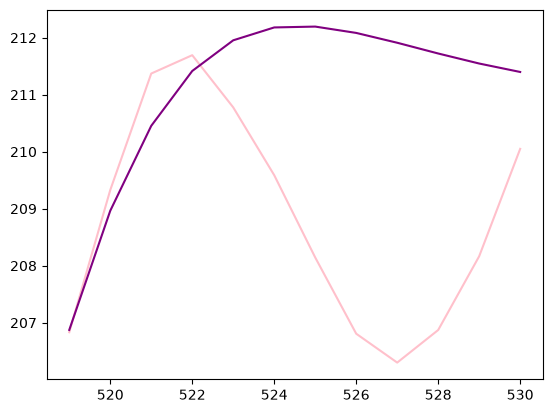

In [14]:
y_test.plot(color="pink")
pred.plot(color="purple")

## Auto ARIMA

In [17]:
from pmdarima.arima import auto_arima

In [18]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)
model = ARIMA(y_train,order=(2,1,2))
model_fit = model.fit()
print('coefficient: %s' % model_fit.params)
predictions = model_fit.predict(start=len(y_train),end=len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test,predictions)
print('test RMSE: %.3f '%error)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-258.744, Time=0.81 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1625.721, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=545.901, Time=0.16 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.36 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1668.139, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-211.845, Time=0.62 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.75 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.13 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.27 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.64 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.83 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.54 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.27 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=-254.857, Time=0.64 sec

Best model:  ARIMA(2,1,2)(0,0,0)[0] intercept
Total fit time: 12.063 seco

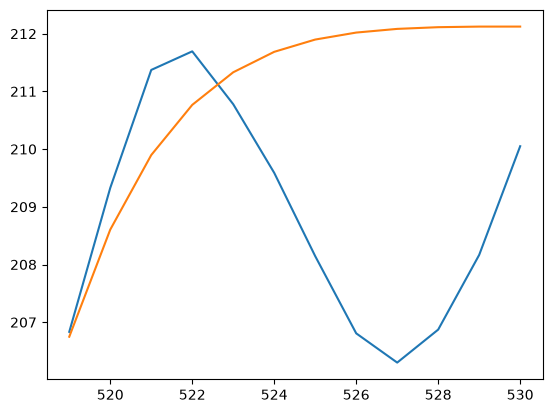

In [19]:
plt.plot(y_test)
plt.plot(predictions)

In [21]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)
model.bse

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-258.744, Time=0.94 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1625.721, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=545.901, Time=0.13 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.33 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1668.139, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-211.845, Time=0.67 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.73 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.20 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.23 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.66 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.69 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.55 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.25 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=-254.857, Time=0.64 sec

Best model:  ARIMA(2,1,2)(0,0,0)[0] intercept
Total fit time: 12.086 seco

<bound method ARIMA.bse of ARIMA(order=(2, 1, 2), scoring_args={}, suppress_warnings=True)>

In [22]:
forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index= y_test.index, columns=["Prediction"])
rms = root_mean_squared_error(y_test, forecast)
print('test RMSE: %.3f '%rms)

test RMSE: 4.213 


In [23]:
# Milk 

In [24]:
df = pd.read_csv("../Datasets/monthly-milk-production-pounds-p.csv",index_col=0)
df.head()

,Milk
Month,
1962-01,589
1962-02,561
1962-03,640
1962-04,656
1962-05,727


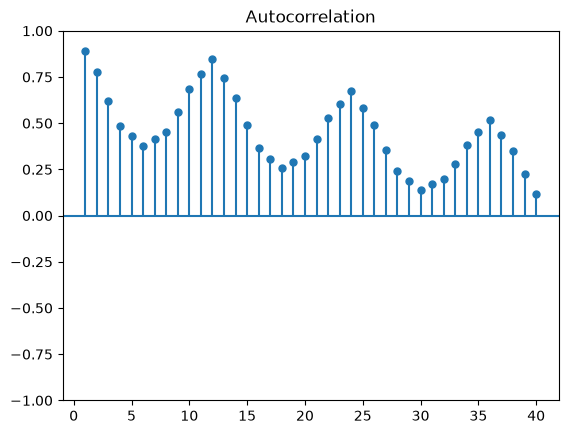

In [26]:
plot_acf(df["Milk"], lags=40, alpha=None,zero=False)
plt.show()

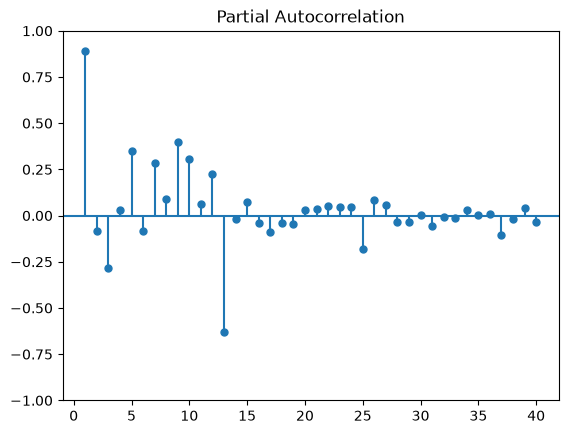

In [27]:
plot_pacf(df["Milk"], lags=40, alpha=None,zero=False)
plt.show()

In [28]:
y = df["Milk"]
y_train = y[:-12]
y_test = y[-12:]

In [29]:
model = ARIMA(y_train, order=(2,1,1))
model_fit = model.fit()
print("Coefficient %s" % model_fit.params)
pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, pred)
print("Test RMSE : %.2f" % error)

Coefficient ar.L1       -0.087896
ar.L2        0.272233
ma.L1        0.120660
sigma2    1882.401208
dtype: float64
Test RMSE : 72.86


C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<Axes: xlabel='Month'>

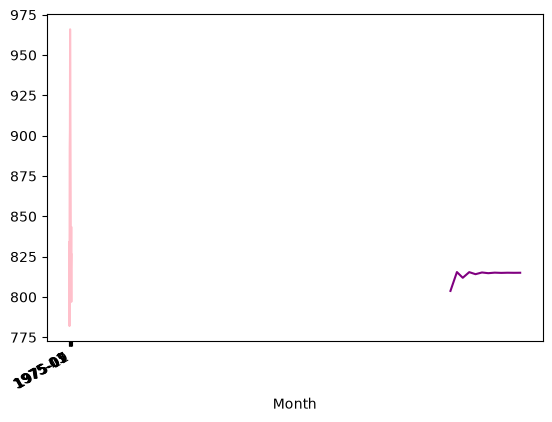

In [30]:
y_test.plot(color="pink")
pred.plot(color="purple")

In [33]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)
model = ARIMA(y_train,order=(2,1,2))
model_fit = model.fit()
print('coefficient: %s' % model_fit.params)
pred = model_fit.predict(start=len(y_train),end=len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test,pred)
print('test RMSE: %.3f '%error)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=1593.685, Time=0.65 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1624.299, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1626.095, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1626.164, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1622.458, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1604.395, Time=0.35 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1618.644, Time=0.27 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.64 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=1572.322, Time=1.07 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.49 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.00 sec
 ARIMA(2,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=0.94 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=1561.833, Time=1.29 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=0.91 sec
 ARIMA(1,1,5)(0,0,0)[0] intercept   : AIC=inf, Time=1.04 s

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


coefficient: ar.L1       -0.313627
ar.L2       -0.449834
ma.L1        0.401520
ma.L2        0.933776
sigma2    1558.970418
dtype: float64
test RMSE: 75.519 


C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_19176\4195933969.py:2: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.plot(pred)


TypeError: tz must be string or tzinfo subclass, not <matplotlib.category.UnitData object at 0x000001EE6EC834D0>.

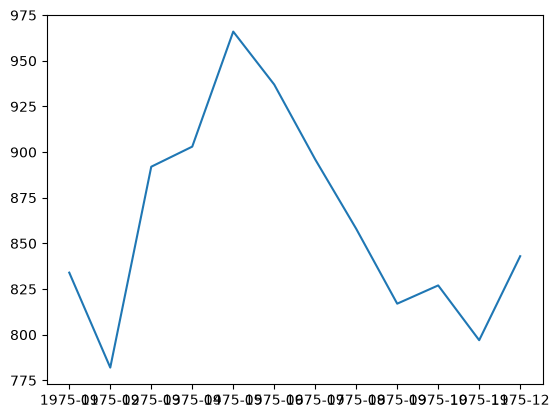

In [34]:
plt.plot(y_test)
plt.plot(pred)

# SARIMA

In [35]:
y_model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True,seasonal=True,m=12)


Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=1000.136, Time=2.53 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=1218.095, Time=0.05 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=1015.855, Time=0.66 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=1104.312, Time=0.63 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=1349.320, Time=0.05 sec
 ARIMA(2,0,2)(0,1,1)[12] intercept   : AIC=998.169, Time=2.02 sec
 ARIMA(2,0,2)(0,1,0)[12] intercept   : AIC=1038.230, Time=0.48 sec
 ARIMA(2,0,2)(0,1,2)[12] intercept   : AIC=1000.125, Time=3.81 sec
 ARIMA(2,0,2)(1,1,0)[12] intercept   : AIC=1012.395, Time=1.79 sec
 ARIMA(2,0,2)(1,1,2)[12] intercept   : AIC=inf, Time=6.86 sec
 ARIMA(1,0,2)(0,1,1)[12] intercept   : AIC=996.457, Time=1.02 sec
 ARIMA(1,0,2)(0,1,0)[12] intercept   : AIC=1036.989, Time=0.31 sec
 ARIMA(1,0,2)(1,1,1)[12] intercept   : AIC=998.423, Time=1.65 sec
 ARIMA(1,0,2)(0,1,2)[12] intercept   : AIC=998.411, Time=1.74 sec
 ARIMA(1,0,2)(1,1,0)[12] int

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=1000.136, Time=2.24 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=1218.095, Time=0.05 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=1015.855, Time=0.55 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=1104.312, Time=0.66 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=1349.320, Time=0.04 sec
 ARIMA(2,0,2)(0,1,1)[12] intercept   : AIC=998.169, Time=1.98 sec
 ARIMA(2,0,2)(0,1,0)[12] intercept   : AIC=1038.230, Time=0.47 sec
 ARIMA(2,0,2)(0,1,2)[12] intercept   : AIC=1000.125, Time=3.14 sec
 ARIMA(2,0,2)(1,1,0)[12] intercept   : AIC=1012.395, Time=1.74 sec
 ARIMA(2,0,2)(1,1,2)[12] intercept   : AIC=inf, Time=5.71 sec
 ARIMA(1,0,2)(0,1,1)[12] intercept   : AIC=996.457, Time=1.10 sec
 ARIMA(1,0,2)(0,1,0)[12] intercept   : AIC=1036.989, Time=0.28 sec
 ARIMA(1,0,2)(1,1,1)[12] intercept   : AIC=998.423, Time=1.66 sec
 ARIMA(1,0,2)(0,1,2)[12] intercept   : AIC=998.411, Time=1.73 sec
 ARIMA(1,0,2)(1,1,0)[12] int

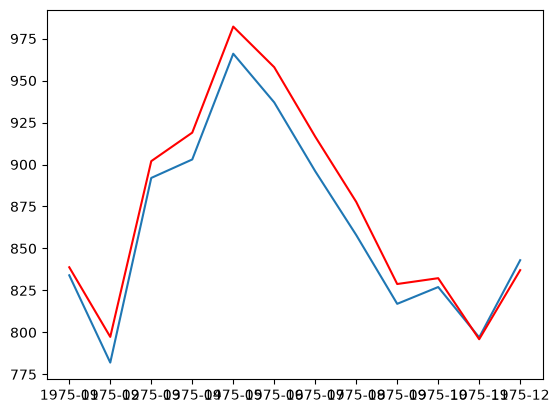

In [37]:
# model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True)

# model.bse

# forecast = model.predict(n_periods=len(y_test))
# forecast = pd.DataFrame(forecast, index = y_test.index, columns=['Prediction'])
# rmse = root_mean_squared_error(y_test, forecast)
# print('Test RMSE: %.3f' % rmse)

# plt.plot(y_test)
# plt.plot(forecast, color='red')
# plt.show()

model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True,seasonal=True,m=12)

forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index = y_test.index, columns=['Prediction'])
rmse = root_mean_squared_error(y_test, forecast)
print('Test RMSE: %.3f' % rmse)

plt.plot(y_test)
plt.plot(forecast, color='red')
plt.show()